# Predicted AHI vs Reference AHI — all 89 LOPO folds

Both indices share **one denominator** and differ only in the numerator, so this
isolates model error from every definition question.

$$T_{\text{sleep}}=\frac{N_{\text{windows}}\times 30 - N_{\text{wake}}\times 30}{3600}\ \text{h}$$

$$\text{reference AHI}=\frac{N_{\text{annotated apnea windows in sleep}}}{T_{\text{sleep}}}
\qquad
\text{predicted AHI}=\frac{N_{\text{predicted apnea windows in sleep}}}{T_{\text{sleep}}}$$

Because the denominator is identical on both sides, the per-patient ratio
$\widehat{\text{AHI}}/\text{AHI}_{\text{ref}}$ reduces exactly to a ratio of window
counts. Agreement here measures **the model against its own annotations** — it
does not measure agreement with the clinical index in column BK, which is
carried alongside for reference but never used as the comparison target.

Both numerators are restricted to sleep-staged epochs; counting positives across
the whole recording while dividing by sleep-only time is a scope mismatch that
previously put five patients above the 120/h physical ceiling.

**Outputs** &rarr; `AHI_calculation_results/` (`tables/`, `figures/`).

## Cell 1 — configuration

In [1]:
# =========================================================================
# CELL 1 — configuration
# =========================================================================
import os, re, glob, json, sys, subprocess, importlib, warnings
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats
from sklearn.metrics import (roc_auc_score, f1_score, average_precision_score,
                             cohen_kappa_score, confusion_matrix)

def _ensure(p, m=None):
    m = m or p
    if importlib.util.find_spec(m) is None:
        try: subprocess.check_call([sys.executable,"-m","pip","install","-q",p])
        except subprocess.CalledProcessError:
            subprocess.check_call([sys.executable,"-m","pip","install","-q",
                                   "--break-system-packages",p])
        importlib.invalidate_caches()
_ensure("openpyxl")
warnings.filterwarnings("ignore")
pd.set_option("display.width",240); pd.set_option("display.max_columns",60)

PROJECT_DIR = "/home/nishant/apneastudyproject"
ANNOT_DIR   = os.path.join(PROJECT_DIR, "NIMHANS Data")
SUBJECT_XLS = os.path.join(PROJECT_DIR, "subject_description.xlsx")
FOLD_DIR    = os.path.join(PROJECT_DIR, "leave_one_out_output", "folds")
OUT_DIR     = os.path.join(PROJECT_DIR, "AHI_calculation_results")
CSV_DIR     = os.path.join(OUT_DIR, "tables")
FIG_DIR     = os.path.join(OUT_DIR, "figures")
for d in (OUT_DIR, CSV_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

WINDOW_SEC      = 30.0
AHI_COL_INDEX   = 62          # column BK
REMAP_AN_TO_SN  = True
EPOCH_OFFSET    = 0
AASM_BINS       = [5.0, 15.0, 30.0]
BAND_NAMES      = ["Normal", "Mild", "Moderate", "Severe"]
BAND_LABELS     = ["Normal\n(<5)", "Mild\n(5-15)", "Moderate\n(15-30)", "Severe\n(>=30)"]
BAND_COLOR      = ["#3B82C4", "#2CA05A", "#E08214", "#C0392B"]
BAND_FILL       = ["#BFD9EF", "#B7E2C6", "#F7D2A5", "#F1B7B0"]

SLEEP_ST = {"N1","N2","N3","N4","REM","R","S1","S2","S3","S4"}
WAKE_ST  = {"WAKE","W","WK"}

def band_idx(v):
    return int(np.searchsorted(AASM_BINS, v, side="right")) if np.isfinite(v) else -1
def band_name(v):
    i = band_idx(v); return BAND_NAMES[i] if i >= 0 else "n/a"

# ---- resolve paths, skipping Excel lock files (~$...) --------------------
def _find_subject_sheet():
    pats = ["subject_description*.xls*", "Subject_Description*.xls*",
            "*subject*descri*.xls*"]
    roots = [PROJECT_DIR,
             os.path.join(PROJECT_DIR, "NIMHANS Data"),
             os.path.join(PROJECT_DIR, "iSLEEPS Dataset"),
             os.path.join(PROJECT_DIR, "data"), os.getcwd()]
    hits = []
    for base in roots:
        if not os.path.isdir(base):
            continue
        for p in pats:
            hits += glob.glob(os.path.join(base, p))
    if os.path.isdir(PROJECT_DIR):                      # depth-limited walk
        d0 = PROJECT_DIR.rstrip(os.sep).count(os.sep)
        for dp, dn, fn in os.walk(PROJECT_DIR):
            if dp.count(os.sep) - d0 > 3:
                dn[:] = []; continue
            for f in fn:
                if ("subject" in f.lower() and "descri" in f.lower()
                        and f.lower().endswith((".xlsx", ".xls"))):
                    hits.append(os.path.join(dp, f))
    good, locks, seen = [], [], set()
    for h in hits:
        h = os.path.abspath(h)
        if h in seen or not os.path.isfile(h):
            continue
        seen.add(h)
        (locks if os.path.basename(h).startswith("~$") else good).append(h)
    return good, locks


def _find_annot_dir():
    for base in (ANNOT_DIR, os.path.join(PROJECT_DIR, "NIMHANS Data"),
                 os.path.join(PROJECT_DIR, "iSLEEPS Dataset"), PROJECT_DIR):
        if os.path.isdir(base) and glob.glob(os.path.join(base, "SN*.xlsx")):
            return base
    return None


print("path check")
_ann = _find_annot_dir()
if _ann is None:
    raise FileNotFoundError(f"No folder with SN*.xlsx found under {PROJECT_DIR}")
ANNOT_DIR = _ann
print(f"  OK  annotations   {ANNOT_DIR} "
      f"({len(glob.glob(os.path.join(ANNOT_DIR,'SN*.xlsx')))} workbooks)")

_good, _locks = _find_subject_sheet()
if _locks:
    print(f"  [!] ignoring {len(_locks)} Excel lock file(s) — close the workbook "
          f"in Excel to remove them:")
    for l in _locks:
        print(f"        {l}")
if not _good:
    print(f"\n  Could not find subject_description.xlsx (lock files don't count).")
    print(f"  PROJECT_DIR = {PROJECT_DIR}")
    print("\n  .xlsx files under PROJECT_DIR (first 30, lock files marked):")
    for f in sorted(glob.glob(os.path.join(PROJECT_DIR, "**", "*.xls*"),
                              recursive=True))[:30]:
        tag = "  [LOCK]" if os.path.basename(f).startswith("~$") else ""
        print(f"     {f}{tag}")
    raise FileNotFoundError("Set SUBJECT_XLS manually and re-run.")
if len(_good) > 1:
    print(f"  [!] {len(_good)} candidates; using the first:")
    for g in _good:
        print(f"        {g}")
SUBJECT_XLS = _good[0]
print(f"  OK  subject sheet {SUBJECT_XLS} ({os.path.getsize(SUBJECT_XLS)/1e3:.1f} KB)")

if not os.path.isdir(FOLD_DIR):
    raise FileNotFoundError(f"folds not found at {FOLD_DIR}")
print(f"  OK  folds         {FOLD_DIR} "
      f"({len(glob.glob(os.path.join(FOLD_DIR,'*.npz')))} .npz)")
print(f"\n  output -> {OUT_DIR}")

plt.rcParams.update({"figure.dpi":110,"savefig.dpi":200,"font.size":9,
                     "font.family":"serif","mathtext.fontset":"dejavuserif",
                     "axes.grid":True,"grid.alpha":.28,"grid.linewidth":.5,
                     "axes.linewidth":.8})

path check
  OK  annotations   /home/nishant/apneastudyproject/NIMHANS Data (100 workbooks)
  [!] ignoring 1 Excel lock file(s) — close the workbook in Excel to remove them:
        /home/nishant/apneastudyproject/NIMHANS Data/~$subject_description.xlsx
  OK  subject sheet /home/nishant/apneastudyproject/NIMHANS Data/subject_description.xlsx (53.5 KB)
  OK  folds         /home/nishant/apneastudyproject/leave_one_out_output/folds (89 .npz)

  output -> /home/nishant/apneastudyproject/AHI_calculation_results


## Cell 2 — clinical AHI (column BK), carried for reference only

In [2]:
SUBJ = pd.read_excel(SUBJECT_XLS)
raw = SUBJ.iloc[:,0].astype(str).str.strip().str.replace(".edf","",regex=False)\
          .str.replace(" ","",regex=False)
def canon(s):
    m = re.fullmatch(r"AN(\d+)", s, re.I)
    if m and REMAP_AN_TO_SN: return f"SN{int(m.group(1))+10}"
    m = re.fullmatch(r"SN(\d+)", s, re.I)
    return f"SN{int(m.group(1))}" if m else s

CLIN = pd.DataFrame({"patient": raw.map(canon), "raw_label": raw,
                     "clinical_ahi": pd.to_numeric(SUBJ.iloc[:,AHI_COL_INDEX],
                                                   errors="coerce")})
CLIN["remapped"] = CLIN.raw_label != CLIN.patient
print(f"column BK -> '{SUBJ.columns[AHI_COL_INDEX]}' | {len(CLIN)} rows | "
      f"{CLIN.remapped.sum()} remapped AN->SN | {CLIN.clinical_ahi.isna().sum()} missing")


column BK -> 'AHI_1_B' | 100 rows | 10 remapped AN->SN | 0 missing


## Cell 3 — sleep profile: wake epochs and the per-epoch sleep mask

The mask is what restricts both numerators to sleep. It is cached in
`SLEEP_MASK`, so re-running this cell is cheap; `del SLEEP_MASK` forces a
rebuild.

In [3]:
def parse_profile(path):
    raw = pd.read_excel(path, sheet_name="Sleep profile", header=None)
    hdr = next((i for i in range(min(40,len(raw)))
                if str(raw.iloc[i,0]).strip().lower()=="time"), 7)
    st = raw.iloc[hdr+1:,1].dropna().astype(str).str.strip().str.upper()
    return (dict(hypno_epochs=len(st),
                 wake_epochs=int(st.isin(WAKE_ST).sum()),
                 sleep_epochs=int(st.isin(SLEEP_ST).sum())),
            st.isin(SLEEP_ST).to_numpy())

SLEEP_MASK = globals().get("SLEEP_MASK") or {}
PROF_ROWS  = globals().get("PROF_ROWS") or []
if not SLEEP_MASK:
    files = sorted(glob.glob(os.path.join(ANNOT_DIR,"SN*.xlsx")),
                   key=lambda p:int(re.search(r"SN(\d+)",p).group(1)))
    print(f"parsing {len(files)} workbooks ...")
    for k,f in enumerate(files,1):
        pid = re.search(r"(SN\d+)", os.path.basename(f)).group(1)
        try:
            row, msk = parse_profile(f); row["patient"] = pid
            PROF_ROWS.append(row); SLEEP_MASK[pid] = msk
        except Exception as ex:
            print(f"  [!] {pid}: {type(ex).__name__}: {ex}")
        if k % 20 == 0: print(f"  ... {k}/{len(files)}")
    print(f"  {len(SLEEP_MASK)} parsed\n")
else:
    print(f"reusing {len(SLEEP_MASK)} cached masks\n")

PROF = pd.DataFrame(PROF_ROWS)
print(PROF[["hypno_epochs","wake_epochs","sleep_epochs"]].describe().round(1).to_string())


parsing 100 workbooks ...
  ... 20/100
  ... 40/100
  ... 60/100
  ... 80/100
  ... 100/100
  100 parsed

       hypno_epochs  wake_epochs  sleep_epochs
count         100.0        100.0         100.0
mean          955.0        250.8         683.5
std           103.7        154.1         173.3
min           472.0         29.0         167.0
25%           901.8        130.5         581.2
50%           953.5        215.0         709.5
75%          1023.8        353.5         811.8
max          1179.0        850.0        1050.0


## Cell 4 — folds: window counts inside sleep, plus per-fold metrics

`f1`, `roc_auc`, `accuracy` and the rest are recomputed from the stored
probabilities and that fold's own validation threshold, so nothing can drift
from the numbers the AHI is derived from.

In [4]:
def sleep_counts(seq, mask, offset=EPOCH_OFFSET):
    m = (mask[offset:] if offset>0 else
         np.concatenate([np.zeros(-offset,bool),mask]) if offset<0 else mask)
    n = min(len(seq), len(m))
    return int((np.asarray(seq[:n]).astype(np.int8) &
                np.asarray(m[:n]).astype(bool)).sum()), n

rows=[]
for f in sorted(glob.glob(os.path.join(FOLD_DIR,"*.npz")),
                key=lambda p:int(re.search(r"SN(\d+)",p).group(1))):
    pid = re.search(r"(SN\d+)", os.path.basename(f)).group(1)
    with np.load(f) as z:
        probs  = np.asarray(z["probs"], float)
        labels = np.asarray(z["labels"]).astype(int)
        thr    = float(z["threshold"])
    pred = (probs >= thr).astype(int)
    two  = len(np.unique(labels)) > 1
    msk  = SLEEP_MASK.get(pid)
    pw = tw = n_al = np.nan
    if msk is not None:
        pw, n_al = sleep_counts(pred, msk)
        tw, _    = sleep_counts(labels, msk)
    rows.append(dict(patient=pid, n_windows=len(labels), threshold=thr,
        pred_win_all=int(pred.sum()), true_win_all=int(labels.sum()),
        pred_win_sleep=pw, true_win_sleep=tw, n_aligned=n_al,
        prevalence=float(labels.mean()),
        accuracy=float((pred==labels).mean()),
        f1=f1_score(labels,pred,zero_division=0) if two else np.nan,
        roc_auc=roc_auc_score(labels,probs) if two else np.nan,
        pr_auc=average_precision_score(labels,probs) if two else np.nan,
        sensitivity=float(pred[labels==1].mean()) if (labels==1).any() else np.nan,
        specificity=float(1-pred[labels==0].mean()) if (labels==0).any() else np.nan,
        precision=float(labels[pred==1].mean()) if (pred==1).any() else np.nan))
FOLD = pd.DataFrame(rows)
print(f"{len(FOLD)} folds | {FOLD.n_windows.sum():,} epochs")
print(f"  annotated windows {int(FOLD.true_win_all.sum()):,} total, "
      f"{int(FOLD.true_win_sleep.sum()):,} in sleep")
print(f"  predicted windows {int(FOLD.pred_win_all.sum()):,} total, "
      f"{int(FOLD.pred_win_sleep.sum()):,} in sleep "
      f"({1-FOLD.pred_win_sleep.sum()/FOLD.pred_win_all.sum():.1%} were wake)")
print(f"  F1 {FOLD.f1.mean():.4f} +/- {FOLD.f1.std():.4f} | "
      f"AUROC {FOLD.roc_auc.mean():.4f} +/- {FOLD.roc_auc.std():.4f}")


89 folds | 85,288 epochs
  annotated windows 20,905 total, 19,877 in sleep
  predicted windows 25,348 total, 21,700 in sleep (14.4% were wake)
  F1 0.6118 +/- 0.1801 | AUROC 0.8812 +/- 0.0686


## Cell 5 — the two indices

Every term is printed so any row can be recomputed by hand.

In [5]:
M = (FOLD.merge(PROF, on="patient", how="left")
          .merge(CLIN[["patient","clinical_ahi","remapped"]], on="patient", how="left"))
M = M.sort_values("patient", key=lambda s:s.str.extract(r"(\d+)")[0].astype(int)).reset_index(drop=True)

M["T_total_h"] = M.n_windows   * WINDOW_SEC / 3600.0
M["T_wake_h"]  = M.wake_epochs * WINDOW_SEC / 3600.0
M["T_sleep_h"] = M.T_total_h - M.T_wake_h
Ts = M.T_sleep_h.replace(0, np.nan)

M["ref_ahi"]  = M.true_win_sleep / Ts          # annotation-derived
M["pred_ahi"] = M.pred_win_sleep / Ts          # model
M["ref_band"]  = M.ref_ahi.map(band_name)
M["pred_band"] = M.pred_ahi.map(band_name)
M["error"]     = M.pred_ahi - M.ref_ahi
M["abs_error"] = M.error.abs()
M["ratio"]     = M.pred_win_sleep / M.true_win_sleep.replace(0, np.nan)
M["len_delta"] = M.n_windows - M.hypno_epochs
M["sleep_eff"] = M.T_sleep_h / M.T_total_h
M["frac_wake"] = 1 - M.pred_win_sleep / M.pred_win_all.replace(0, np.nan)

print("="*118); print("  TERMS OF THE FORMULA"); print("="*118)
au = M[["patient","n_windows","T_total_h","wake_epochs","T_wake_h","T_sleep_h",
        "true_win_sleep","ref_ahi","pred_win_sleep","pred_ahi","error",
        "clinical_ahi"]]
print(au.round(3).to_string(index=False))
au.to_csv(os.path.join(CSV_DIR,"table1_formula_terms.csv"), index=False)

r0 = M.iloc[0]
print(f"\n  worked example - {r0.patient}")
print(f"    T_total  = {int(r0.n_windows)} x 30 / 3600 = {r0.T_total_h:.4f} h")
print(f"    T_wake   = {int(r0.wake_epochs)} x 30 / 3600 = {r0.T_wake_h:.4f} h")
print(f"    T_sleep  = {r0.T_total_h:.4f} - {r0.T_wake_h:.4f} = {r0.T_sleep_h:.4f} h")
print(f"    ref_ahi  = {int(r0.true_win_sleep)} / {r0.T_sleep_h:.4f} = {r0.ref_ahi:.2f} /h")
print(f"    pred_ahi = {int(r0.pred_win_sleep)} / {r0.T_sleep_h:.4f} = {r0.pred_ahi:.2f} /h")

print("\n  plausibility")
print(f"    apnea time > sleep time : {(M.pred_win_sleep*WINDOW_SEC > M.T_sleep_h*3600).sum()} patients")
print(f"    pred_ahi above 120/h    : {(M.pred_ahi>120).sum()}")
print(f"    max ref {M.ref_ahi.max():.1f} | max pred {M.pred_ahi.max():.1f}")
print(f"\n  reference band counts: {M.ref_band.value_counts().reindex(BAND_NAMES).to_dict()}")


  TERMS OF THE FORMULA
patient  n_windows  T_total_h  wake_epochs  T_wake_h  T_sleep_h  true_win_sleep  ref_ahi  pred_win_sleep  pred_ahi   error  clinical_ahi
    SN2       1117      9.308          628     5.233      4.075              34    8.344              40     9.816   1.472           6.5
    SN3        973      8.108          147     1.225      6.883             376   54.625             267    38.789 -15.835          41.1
    SN4       1025      8.542          104     0.867      7.675             451   58.762             649    84.560  25.798          39.1
    SN5        829      6.908           59     0.492      6.417              28    4.364              62     9.662   5.299           1.9
    SN6        948      7.900          328     2.733      5.167              55   10.645              91    17.613   6.968           6.2
    SN7        947      7.892          149     1.242      6.650              87   13.083             118    17.744   4.662           8.9
    SN8       1092

## Cell 6 — agreement metrics

Pearson $r$ with a Fisher-$z$ confidence interval, $R^2$, Lin's concordance
(CCC), ICC(2,1) for absolute agreement, RMSE, MAE, ordinary least squares fit,
and Bland–Altman bias with 95% limits.

CCC and ICC differ from $r$ by penalising departure from the identity line, so
the gap between $r$ and CCC is the systematic bias.

In [6]:
def ccc(x, y):
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(ddof=0), y.var(ddof=0)
    cov = ((x-mx)*(y-my)).mean()
    return 2*cov / (vx + vy + (mx-my)**2)

def icc21(x, y):
    """Two-way random effects, absolute agreement, single measurement."""
    Y = np.column_stack([x, y]); n, k = Y.shape
    gm = Y.mean()
    MSR = k*((Y.mean(1)-gm)**2).sum()/(n-1)
    MSC = n*((Y.mean(0)-gm)**2).sum()/(k-1)
    SSE = ((Y - Y.mean(1,keepdims=True) - Y.mean(0,keepdims=True) + gm)**2).sum()
    MSE = SSE/((n-1)*(k-1))
    return (MSR-MSE)/(MSR + (k-1)*MSE + k*(MSC-MSE)/n)

ok = np.isfinite(M.ref_ahi) & np.isfinite(M.pred_ahi)
x, y = M.ref_ahi[ok].values, M.pred_ahi[ok].values
n = len(x)
r, p = stats.pearsonr(x, y)
z, se = np.arctanh(r), 1/np.sqrt(n-3)
r_lo, r_hi = np.tanh(z-1.96*se), np.tanh(z+1.96*se)
rho, p_s = stats.spearmanr(x, y)
slope, intercept, *_ = stats.linregress(x, y)
d = y - x
AG = dict(n=n, pearson_r=r, r_lo95=r_lo, r_hi95=r_hi, p=p, r_squared=r**2,
          spearman=rho, ccc=ccc(x,y), icc21=icc21(x,y),
          rmse=float(np.sqrt((d**2).mean())), mae=float(np.abs(d).mean()),
          bias=float(d.mean()), loa_lo=float(d.mean()-1.96*d.std(ddof=1)),
          loa_hi=float(d.mean()+1.96*d.std(ddof=1)),
          ols_slope=slope, ols_intercept=intercept,
          R2_agreement=1-np.sum(d**2)/np.sum((x-x.mean())**2))

print("="*70); print("  AGREEMENT: predicted AHI vs reference AHI"); print("="*70)
for k_,v in AG.items():
    print(f"  {k_:16s} {v if isinstance(v,int) else round(v,4)}")
pd.DataFrame([AG]).to_csv(os.path.join(CSV_DIR,"table2_agreement.csv"), index=False)

tb, pb = [band_idx(v) for v in x], [band_idx(v) for v in y]
CM = confusion_matrix(tb, pb, labels=[0,1,2,3])
acc  = float(np.trace(CM)/CM.sum())
k_un = cohen_kappa_score(tb, pb)
k_qw = cohen_kappa_score(tb, pb, weights="quadratic")
w1   = float(np.mean(np.abs(np.array(tb)-np.array(pb)) <= 1))
print(f"\n  severity: accuracy {acc:.3f} | within +/-1 class {w1:.3f} | "
      f"kappa {k_un:.3f} | kappa_w(quad) {k_qw:.3f}")


  AGREEMENT: predicted AHI vs reference AHI
  n                89
  pearson_r        0.9128
  r_lo95           0.8698
  r_hi95           0.942
  p                0.0
  r_squared        0.8331
  spearman         0.903
  ccc              0.9033
  icc21            0.9043
  rmse             11.498
  mae              8.4786
  bias             3.2419
  loa_lo           -18.5024
  loa_hi           24.9861
  ols_slope        0.9817
  ols_intercept    3.936
  R2_agreement     0.7899

  severity: accuracy 0.742 | within +/-1 class 1.000 | kappa 0.563 | kappa_w(quad) 0.838


## Cell 7 — Figure 1: agreement scatter

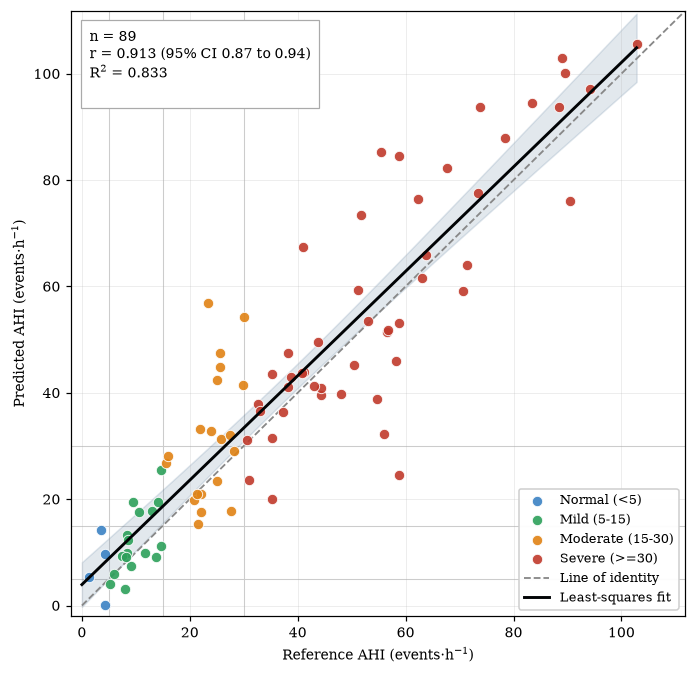

In [13]:
fig, ax = plt.subplots(figsize=(6.4,6.2))
for i,(bn,bl) in enumerate(zip(BAND_NAMES, BAND_LABELS)):
    m = np.array([band_idx(v)==i for v in x])
    if m.any():
        ax.scatter(x[m], y[m], s=46, c=BAND_COLOR[i], alpha=.9, lw=.6,
                   edgecolors="white", zorder=3,
                   label=f"{bn} ({bl.split(chr(10))[1].strip('()')})")
hi = max(x.max(), y.max())*1.06
ax.plot([0,hi],[0,hi], ls="--", c="#888888", lw=1.2, zorder=2,
        label="Line of identity")
xs = np.linspace(0, x.max(), 100)
ax.plot(xs, intercept+slope*xs, c="#010305", lw=1.9, zorder=4,
        label="Least-squares fit")
sx = np.sqrt(((y-(intercept+slope*x))**2).sum()/(n-2))
se_fit = sx*np.sqrt(1/n + (xs-x.mean())**2/((x-x.mean())**2).sum())
ax.fill_between(xs, intercept+slope*xs-1.96*se_fit, intercept+slope*xs+1.96*se_fit,
                color="#1F4E79", alpha=.13, zorder=1)
for v in AASM_BINS:
    ax.axvline(v, c="#CCCCCC", lw=.7, zorder=0)
    ax.axhline(v, c="#CCCCCC", lw=.7, zorder=0)
txt = (f"n = {n}\n"
       f"r = {r:.3f} (95% CI {r_lo:.2f} to {r_hi:.2f})\n"
       f"R$^2$ = {r**2:.3f}\n"
       
       )
ax.text(.03,.97, txt, transform=ax.transAxes, va="top", fontsize=9.2,
        bbox=dict(fc="white", ec="#AAAAAA", lw=.8, pad=5.5))
ax.set_xlabel("Reference AHI (events$\\cdot$h$^{-1}$)")
ax.set_ylabel("Predicted AHI (events$\\cdot$h$^{-1}$)")
ax.set_xlim(-2,hi); ax.set_ylim(-2,hi)
ax.legend(loc="lower right", fontsize=8.4, framealpha=.95)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR,"fig1_agreement_scatter.png"), bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig1_agreement_scatter.pdf"), bbox_inches="tight")
plt.show()

## Cell 8 — Figure 2: severity confusion matrix

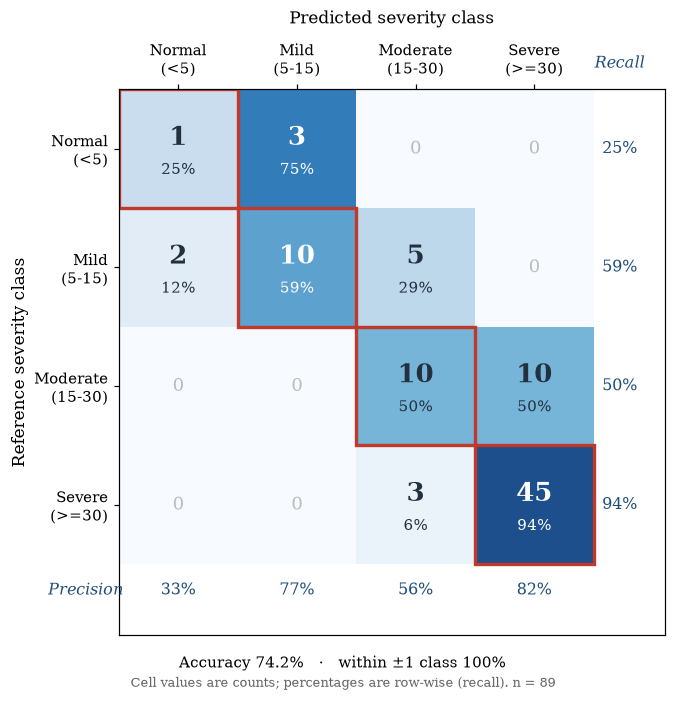

In [8]:
fig, ax = plt.subplots(figsize=(6.6,6.4))
rowsum = CM.sum(1, keepdims=True)
norm = CM/np.maximum(rowsum,1)
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1, alpha=.92)
for i in range(4):
    for j in range(4):
        c = CM[i,j]
        if c == 0:
            ax.text(j,i,"0",ha="center",va="center",fontsize=12,color="#BBBBBB")
        else:
            col = "white" if norm[i,j] > .55 else "#22303F"
            ax.text(j,i-.09,f"{c}",ha="center",va="center",fontsize=17,
                    fontweight="bold",color=col)
            ax.text(j,i+.18,f"{100*norm[i,j]:.0f}%",ha="center",va="center",
                    fontsize=9.5,color=col)
    ax.add_patch(Rectangle((i-.5,i-.5),1,1,fill=False,ec="#C0392B",lw=2.2))
ax.set_xticks(range(4)); ax.set_xticklabels(BAND_LABELS, fontsize=10)
ax.set_yticks(range(4)); ax.set_yticklabels(BAND_LABELS, fontsize=10)
ax.xaxis.set_ticks_position("top"); ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted severity class", fontsize=11, labelpad=12)
ax.set_ylabel("Reference severity class", fontsize=11)
ax.grid(False)
rec = np.diag(CM)/np.maximum(CM.sum(1),1)
pre = np.diag(CM)/np.maximum(CM.sum(0),1)
for i,v in enumerate(rec):
    ax.text(3.72,i,f"{100*v:.0f}%",ha="center",va="center",fontsize=10.5,color="#1F4E79")
ax.text(3.72,-.72,"Recall",ha="center",va="center",fontsize=10.5,
        color="#1F4E79",style="italic")
for j,v in enumerate(pre):
    ax.text(j,3.72,f"{100*v:.0f}%",ha="center",va="center",fontsize=10.5,color="#1F4E79")
ax.text(-.78,3.72,"Precision",ha="center",va="center",fontsize=10.5,
        color="#1F4E79",style="italic")
ax.set_xlim(-.5,4.1); ax.set_ylim(4.1,-.5)
fig.text(.5,.045,f"Accuracy {100*acc:.1f}%   $\\cdot$   within $\\pm$1 class "
         f"{100*w1:.0f}%", ha="center", fontsize=10)
fig.text(.5,.018,"Cell values are counts; percentages are row-wise (recall). "
         f"n = {n}", ha="center", fontsize=8.6, color="#666666")
fig.tight_layout(rect=[0,.07,1,1])
fig.savefig(os.path.join(FIG_DIR,"fig2_severity_confusion.png"), bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig2_severity_confusion.pdf"), bbox_inches="tight")
plt.show()
pd.DataFrame(CM, index=[f"ref {b}" for b in BAND_NAMES],
             columns=[f"pred {b}" for b in BAND_NAMES]).to_csv(
    os.path.join(CSV_DIR,"table3_severity_confusion.csv"))

## Cell 9 — Figures 3–8: Bland–Altman, operating point, bands, diagnostics

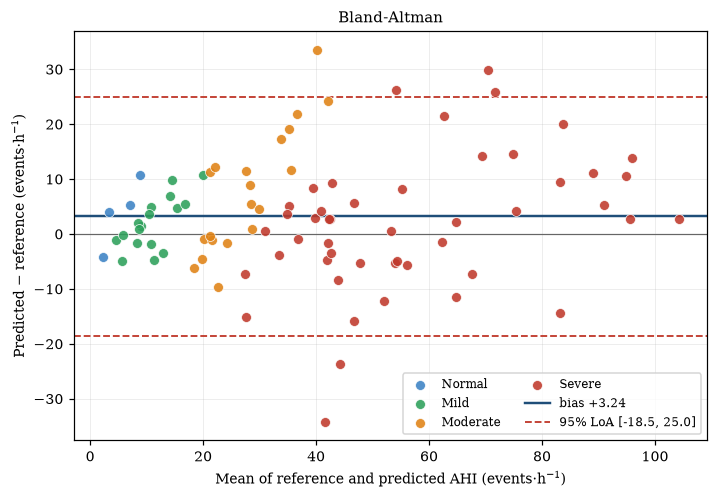

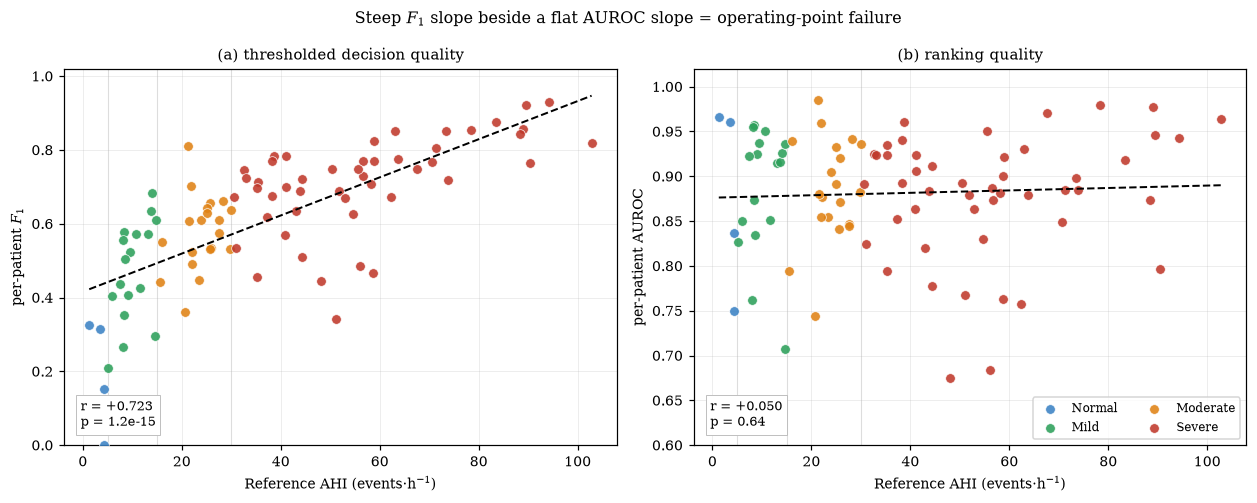

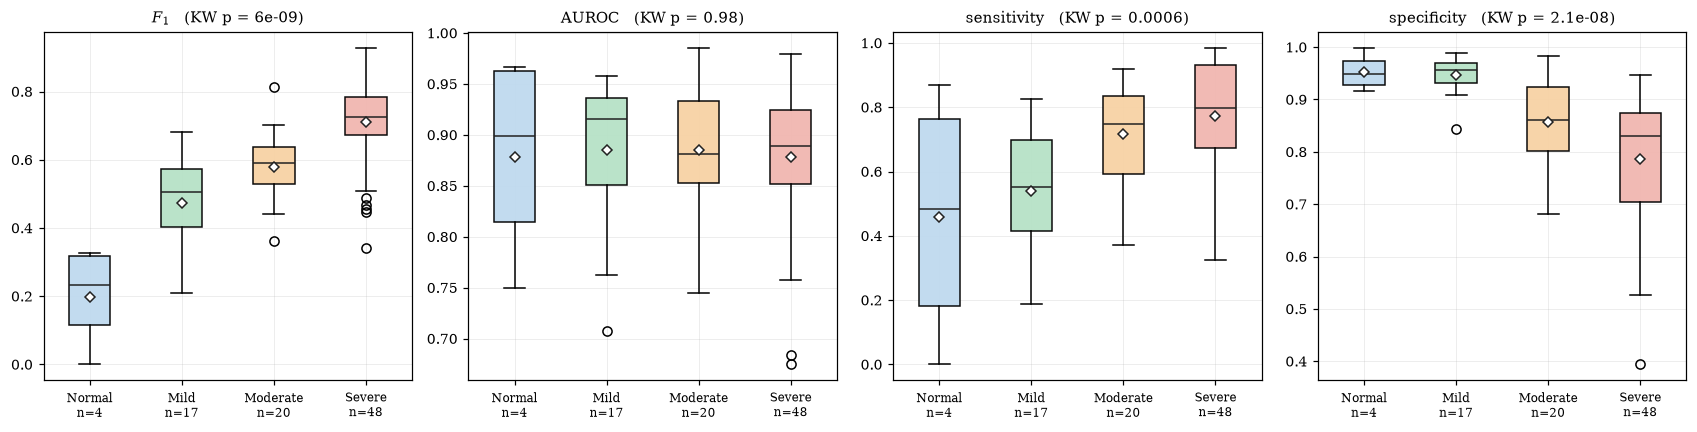

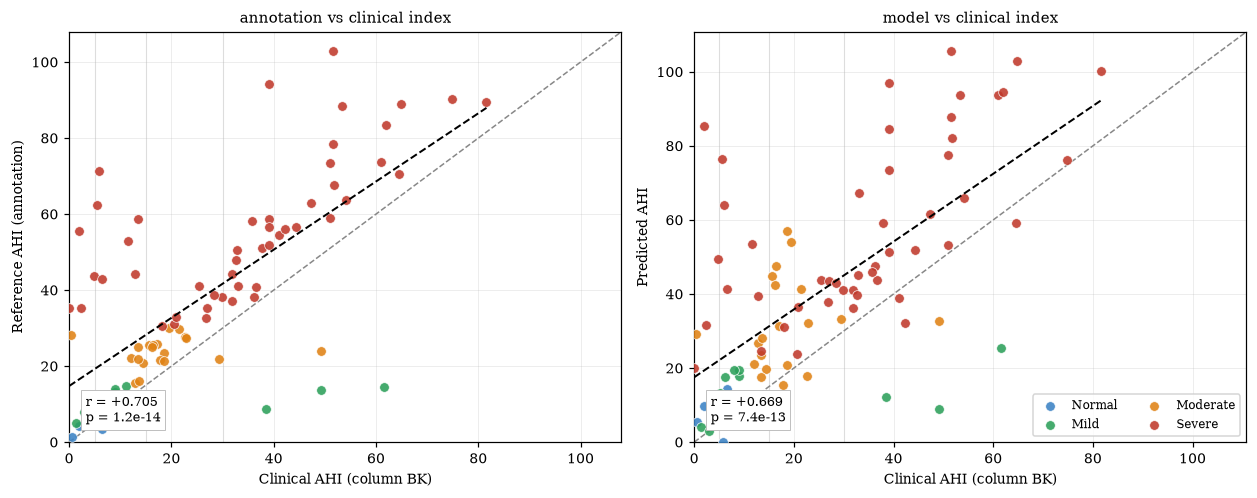

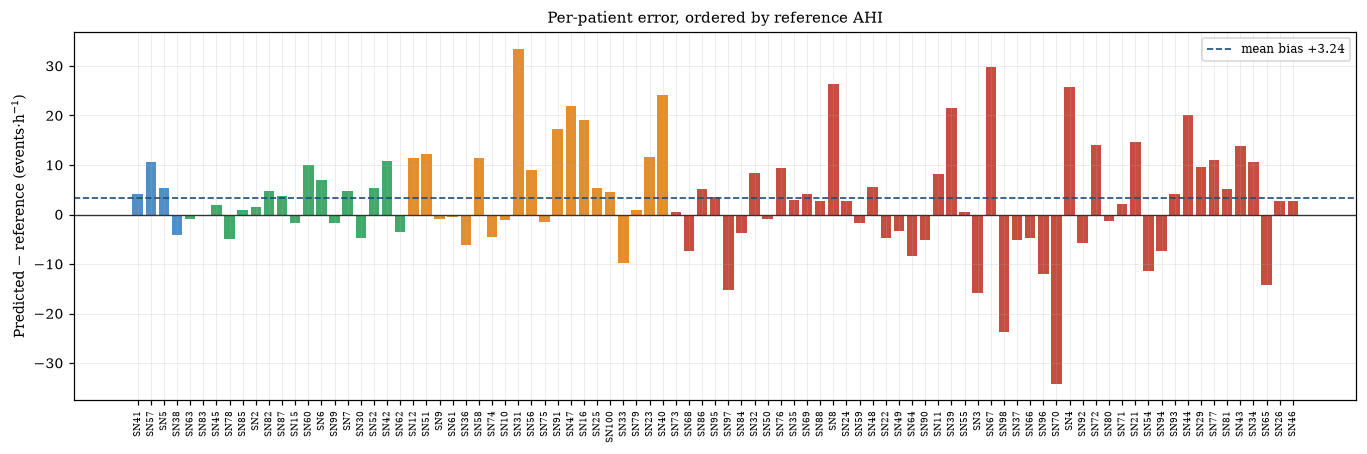

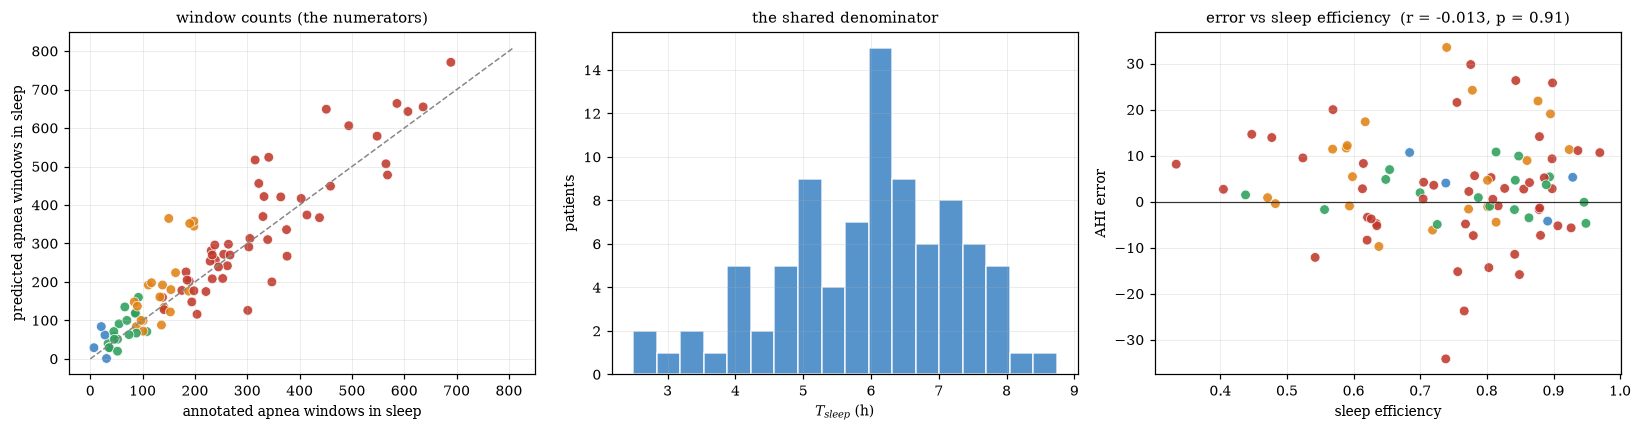

figures -> /home/nishant/apneastudyproject/AHI_calculation_results/figures


In [9]:
def bscat(ax, xv, yv, xl, yl, ttl, ident=False, band_by=None):
    bb = band_by if band_by is not None else M.ref_band
    for i,bn in enumerate(BAND_NAMES):
        m = (bb == bn).values
        if m.any():
            ax.scatter(xv[m], yv[m], s=40, c=BAND_COLOR[i], alpha=.88, lw=.5,
                       edgecolors="white", label=bn, zorder=3)
    f = np.isfinite(xv)&np.isfinite(yv)
    if f.sum() > 2:
        z_ = np.polyfit(xv[f],yv[f],1); xs_ = np.linspace(np.nanmin(xv),np.nanmax(xv),50)
        rr,pp = stats.pearsonr(xv[f],yv[f])
        ax.plot(xs_, np.polyval(z_,xs_), "k--", lw=1.3, zorder=4)
        ax.text(.03,.04,f"r = {rr:+.3f}\np = {pp:.2g}", transform=ax.transAxes,
                fontsize=8.4, va="bottom",
                bbox=dict(fc="white",ec="#BBBBBB",lw=.6,pad=3))
    if ident:
        h_ = max(np.nanmax(xv),np.nanmax(yv))*1.05
        ax.plot([0,h_],[0,h_],ls="--",c="#888888",lw=1)
        ax.set_xlim(0,h_); ax.set_ylim(0,h_)
    for v in AASM_BINS: ax.axvline(v,c="#DDDDDD",lw=.7,zorder=0)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(ttl, fontsize=10)

# --- Fig 3 Bland-Altman
fig, ax = plt.subplots(figsize=(6.6,4.6))
mean_, diff_ = (x+y)/2, y-x
b_, s_ = diff_.mean(), diff_.std(ddof=1)
for i,bn in enumerate(BAND_NAMES):
    m = np.array([band_idx(v)==i for v in x])
    if m.any(): ax.scatter(mean_[m],diff_[m],s=42,c=BAND_COLOR[i],alpha=.88,
                           lw=.5,edgecolors="white",label=bn,zorder=3)
ax.axhline(b_,c="#1F4E79",lw=1.6,label=f"bias {b_:+.2f}")
ax.axhline(b_+1.96*s_,c="#C0392B",ls="--",lw=1.2,
           label=f"95% LoA [{b_-1.96*s_:.1f}, {b_+1.96*s_:.1f}]")
ax.axhline(b_-1.96*s_,c="#C0392B",ls="--",lw=1.2)
ax.axhline(0,c="#666666",lw=.8)
ax.set_xlabel("Mean of reference and predicted AHI (events$\\cdot$h$^{-1}$)")
ax.set_ylabel("Predicted $-$ reference (events$\\cdot$h$^{-1}$)")
ax.set_title("Bland-Altman", fontsize=10); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig3_bland_altman.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig3_bland_altman.pdf"),bbox_inches="tight"); plt.show()

# --- Fig 4 operating point
fig, axes = plt.subplots(1,2,figsize=(11.5,4.6))
bscat(axes[0], M.ref_ahi.values, M.f1.values, "Reference AHI (events$\\cdot$h$^{-1}$)",
      "per-patient $F_1$", "(a) thresholded decision quality")
bscat(axes[1], M.ref_ahi.values, M.roc_auc.values, "Reference AHI (events$\\cdot$h$^{-1}$)",
      "per-patient AUROC", "(b) ranking quality")
axes[0].set_ylim(0,1.02); axes[1].set_ylim(.6,1.02); axes[1].legend(fontsize=8,ncol=2)
fig.suptitle("Steep $F_1$ slope beside a flat AUROC slope = operating-point failure",
             fontsize=10.5)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig4_f1_auroc_vs_refahi.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig4_f1_auroc_vs_refahi.pdf"),bbox_inches="tight"); plt.show()

# --- Fig 5 metrics by reference band
fig, axes = plt.subplots(1,4,figsize=(15.5,4.0))
for ax,c,ttl in ((axes[0],"f1","$F_1$"),(axes[1],"roc_auc","AUROC"),
                 (axes[2],"sensitivity","sensitivity"),(axes[3],"specificity","specificity")):
    dat,lab_=[],[]
    for i,bn in enumerate(BAND_NAMES):
        v = M.loc[M.ref_band==bn,c].dropna().values
        if len(v): dat.append(v); lab_.append(f"{bn}\nn={len(v)}")
    bp = ax.boxplot(dat, tick_labels=lab_, patch_artist=True, showmeans=True,
                    medianprops=dict(color="#222222"),
                    meanprops=dict(marker="D",mfc="white",mec="#222222",ms=5))
    for pt,cl in zip(bp["boxes"],BAND_FILL): pt.set_facecolor(cl); pt.set_alpha(.95)
    if len(dat)>1:
        H,pv = stats.kruskal(*dat); ax.set_title(f"{ttl}   (KW p = {pv:.2g})", fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig5_metrics_by_band.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig5_metrics_by_band.pdf"),bbox_inches="tight"); plt.show()

# --- Fig 6 reference vs clinical (the definition gap)
fig, axes = plt.subplots(1,2,figsize=(11.5,4.6))
bscat(axes[0], M.clinical_ahi.values, M.ref_ahi.values, "Clinical AHI (column BK)",
      "Reference AHI (annotation)", "annotation vs clinical index", ident=True)
bscat(axes[1], M.clinical_ahi.values, M.pred_ahi.values, "Clinical AHI (column BK)",
      "Predicted AHI", "model vs clinical index", ident=True)
axes[1].legend(fontsize=8,ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig6_vs_clinical.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig6_vs_clinical.pdf"),bbox_inches="tight"); plt.show()

# --- Fig 7 per-patient error, sorted
fig, ax = plt.subplots(figsize=(12.5,4.2))
srt = M.sort_values("ref_ahi").reset_index(drop=True)
cols = [BAND_COLOR[band_idx(v)] for v in srt.ref_ahi]
ax.bar(range(len(srt)), srt.error, color=cols, alpha=.9)
ax.axhline(0,c="#333333",lw=.9)
ax.axhline(b_,c="#1F4E79",ls="--",lw=1.1,label=f"mean bias {b_:+.2f}")
ax.set_xticks(range(len(srt))); ax.set_xticklabels(srt.patient,rotation=90,fontsize=6)
ax.set_ylabel("Predicted $-$ reference (events$\\cdot$h$^{-1}$)")
ax.set_title("Per-patient error, ordered by reference AHI", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig7_per_patient_error.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig7_per_patient_error.pdf"),bbox_inches="tight"); plt.show()

# --- Fig 8 window counts + sleep architecture
fig, axes = plt.subplots(1,3,figsize=(15,4.0))
axes[0].scatter(M.true_win_sleep, M.pred_win_sleep, s=40,
                c=[BAND_COLOR[band_idx(v)] for v in M.ref_ahi],
                alpha=.88, lw=.5, edgecolors="white")
hh = max(M.true_win_sleep.max(), M.pred_win_sleep.max())*1.05
axes[0].plot([0,hh],[0,hh],ls="--",c="#888888",lw=1)
axes[0].set_xlabel("annotated apnea windows in sleep")
axes[0].set_ylabel("predicted apnea windows in sleep")
axes[0].set_title("window counts (the numerators)", fontsize=10)
axes[1].hist(M.T_sleep_h.dropna(), bins=18, color="#3B82C4", alpha=.85, edgecolor="white")
axes[1].set_xlabel("$T_{sleep}$ (h)"); axes[1].set_ylabel("patients")
axes[1].set_title("the shared denominator", fontsize=10)
axes[2].scatter(M.sleep_eff, M.error, s=40,
                c=[BAND_COLOR[band_idx(v)] for v in M.ref_ahi],
                alpha=.88, lw=.5, edgecolors="white")
axes[2].axhline(0,c="#333333",lw=.8)
f_ = np.isfinite(M.sleep_eff)&np.isfinite(M.error)
rr,pp = stats.pearsonr(M.sleep_eff[f_], M.error[f_])
axes[2].set_xlabel("sleep efficiency"); axes[2].set_ylabel("AHI error")
axes[2].set_title(f"error vs sleep efficiency  (r = {rr:+.3f}, p = {pp:.2g})", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"fig8_diagnostics.png"),bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR,"fig8_diagnostics.pdf"),bbox_inches="tight"); plt.show()
print(f"figures -> {FIG_DIR}")


## Cell 10 — final per-patient table

`predicted_ahi`, `reference_ahi`, `clinical_ahi` and `f1` for every patient,
with the supporting counts.

In [10]:
FINAL = pd.DataFrame({
    "patient":        M.patient,
    "predicted_ahi":  M.pred_ahi.round(3),
    "reference_ahi":  M.ref_ahi.round(3),
    "clinical_ahi":   M.clinical_ahi,
    "f1":             M.f1.round(4),
    "accuracy":       M.accuracy.round(4),
    "roc_auc":        M.roc_auc.round(4),
    "sensitivity":    M.sensitivity.round(4),
    "specificity":    M.specificity.round(4),
    "precision":      M.precision.round(4),
    "prevalence":     M.prevalence.round(4),
    "threshold":      M.threshold.round(4),
    "pred_windows_sleep": M.pred_win_sleep,
    "true_windows_sleep": M.true_win_sleep,
    "n_windows":      M.n_windows,
    "wake_epochs":    M.wake_epochs,
    "T_total_h":      M.T_total_h.round(4),
    "T_wake_h":       M.T_wake_h.round(4),
    "T_sleep_h":      M.T_sleep_h.round(4),
    "ref_band":       M.ref_band,
    "pred_band":      M.pred_band,
    "band_match":     np.where(M.ref_band==M.pred_band,"yes","NO"),
    "error":          M.error.round(3),
    "abs_error":      M.abs_error.round(3),
}).sort_values("reference_ahi").reset_index(drop=True)

print("="*140)
print(f"  PER-PATIENT: PREDICTED / REFERENCE / CLINICAL AHI + F1   (n = {len(FINAL)})")
print("="*140)
show = ["patient","predicted_ahi","reference_ahi","clinical_ahi","f1","accuracy",
        "roc_auc","ref_band","pred_band","band_match","error"]
with pd.option_context("display.max_rows", None):
    print(FINAL[show].to_string(index=False))

out = os.path.join(CSV_DIR, "per_patient_ahi_table.csv")
FINAL.to_csv(out, index=False)
M.to_csv(os.path.join(CSV_DIR, "master_per_patient.csv"), index=False)

print("\n" + "="*70); print("  SUMMARY"); print("="*70)
print(f"  reference AHI   mean {FINAL.reference_ahi.mean():7.2f} +/- {FINAL.reference_ahi.std():5.2f}")
print(f"  predicted AHI   mean {FINAL.predicted_ahi.mean():7.2f} +/- {FINAL.predicted_ahi.std():5.2f}")
print(f"  clinical AHI    mean {FINAL.clinical_ahi.mean():7.2f} +/- {FINAL.clinical_ahi.std():5.2f}")
print(f"\n  pred vs reference : r {AG['pearson_r']:+.4f} | CCC {AG['ccc']:.4f} | "
      f"ICC {AG['icc21']:.4f} | MAE {AG['mae']:.2f} | bias {AG['bias']:+.2f}")
rc,_ = stats.pearsonr(*[v[np.isfinite(M.ref_ahi)&np.isfinite(M.clinical_ahi)]
                        for v in (M.ref_ahi.values, M.clinical_ahi.values)])
print(f"  reference vs clinical : r {rc:+.4f}   <- ceiling on any clinical-AHI claim")
print(f"\n  band agreement {(FINAL.band_match=='yes').sum()}/{len(FINAL)} "
      f"({(FINAL.band_match=='yes').mean():.1%}) | kappa_w {k_qw:.4f}")
print(f"\n  F1 {FINAL.f1.mean():.4f} +/- {FINAL.f1.std():.4f}   "
      f"AUROC {FINAL.roc_auc.mean():.4f} +/- {FINAL.roc_auc.std():.4f}")
print(f"\n  saved -> {out}")
for f in sorted(glob.glob(os.path.join(CSV_DIR,"*.csv"))):
    print(f"    {os.path.basename(f):36s} {os.path.getsize(f)/1e3:7.1f} KB")
print(f"    figures/  {len(glob.glob(os.path.join(FIG_DIR,'*.png')))} PNG + "
      f"{len(glob.glob(os.path.join(FIG_DIR,'*.pdf')))} PDF")


  PER-PATIENT: PREDICTED / REFERENCE / CLINICAL AHI + F1   (n = 89)
patient  predicted_ahi  reference_ahi  clinical_ahi     f1  accuracy  roc_auc ref_band pred_band band_match   error
   SN41          5.337          1.288           0.6 0.3265    0.9626   0.9666   Normal      Mild         NO   4.049
   SN57         14.237          3.559           6.5 0.3150    0.9159   0.9609   Normal      Mild         NO  10.678
    SN5          9.662          4.364           1.9 0.1522    0.9059   0.8363   Normal      Mild         NO   5.299
   SN38          0.141          4.366           5.8 0.0000    0.9665   0.7501   Normal    Normal        yes  -4.225
   SN63          4.133          5.131           1.4 0.2090    0.9494   0.8265     Mild    Normal         NO  -0.998
   SN83          5.834          5.949          16.2 0.4037    0.9414   0.8504     Mild      Mild        yes  -0.114
   SN45          9.393          7.449           4.8 0.4370    0.9367   0.9227     Mild      Mild        yes   1.943
   S

per-fold metrics against reference AHI
  roc_auc  vs reference AHI: Pearson r = +0.0497 (p = 0.644) | Kruskal-Wallis H = 0.212 (p = 0.9756)


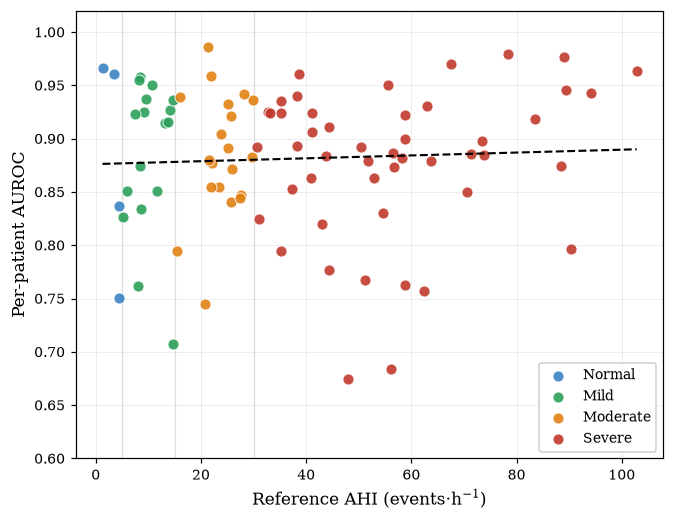

  f1       vs reference AHI: Pearson r = +0.7235 (p = 1.164e-15) | Kruskal-Wallis H = 41.172 (p = 6.012e-09)


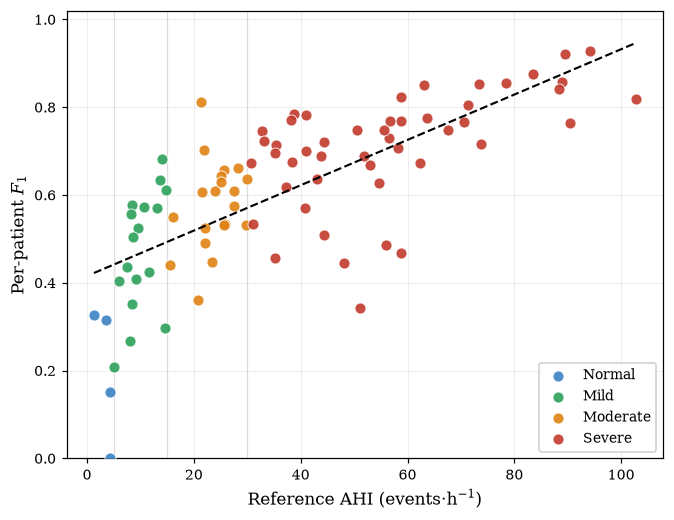


pooled epochs: 85,288
  TN 55,095   FP 9,288   FN 4,845   TP 16,060
  accuracy 0.8343 | sensitivity 0.7682 | specificity 0.8557 | precision 0.6336


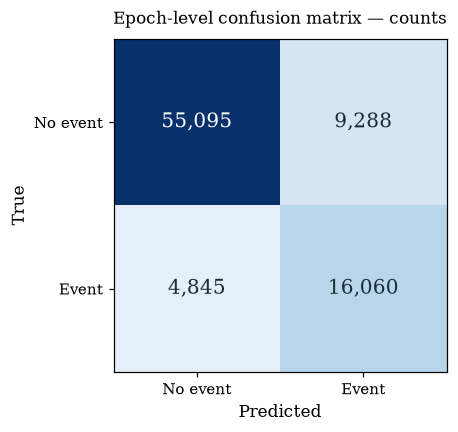

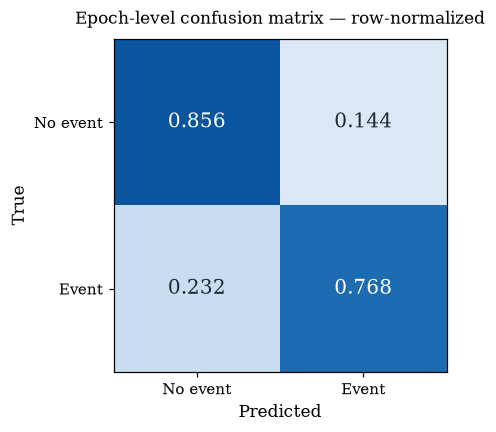


saved -> /home/nishant/apneastudyproject/AHI_calculation_results/standalone_figures
  std_auroc_vs_reference_ahi.pdf
  std_auroc_vs_reference_ahi.png
  std_confusion_counts.pdf
  std_confusion_counts.png
  std_confusion_row_normalized.pdf
  std_confusion_row_normalized.png
  std_f1_vs_reference_ahi.pdf
  std_f1_vs_reference_ahi.png


In [15]:
# =========================================================================
# CELL 11 — standalone figures: AUROC / F1 vs reference AHI, confusion matrix
# =========================================================================
import os, glob, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import confusion_matrix

STD_DIR = os.path.join(OUT_DIR, "standalone_figures")
os.makedirs(STD_DIR, exist_ok=True)


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(STD_DIR, f"{name}.{ext}"),
                    dpi=250, bbox_inches="tight")
    plt.show()


def metric_vs_refahi(col, ylab, name, ylim):
    fig, ax = plt.subplots(figsize=(6.2, 4.8))
    xv, yv = M.ref_ahi.values, M[col].values
    for i, bn in enumerate(BAND_NAMES):
        m = (M.ref_band == bn).values & np.isfinite(yv)
        if m.any():
            ax.scatter(xv[m], yv[m], s=52, c=BAND_COLOR[i], alpha=.9, lw=.6,
                       edgecolors="white", zorder=3, label=bn)
    f = np.isfinite(xv) & np.isfinite(yv)
    if f.sum() > 2:
        sl, ic, *_ = stats.linregress(xv[f], yv[f])
        xs = np.linspace(xv[f].min(), xv[f].max(), 60)
        ax.plot(xs, ic + sl*xs, "k--", lw=1.4, zorder=4)
        # stats still reported to the console, not drawn on the figure
        r, p = stats.pearsonr(xv[f], yv[f])
        grp = [M.loc[(M.ref_band == b) & np.isfinite(M[col]), col].values
               for b in BAND_NAMES]
        grp = [g for g in grp if len(g)]
        H, pk = stats.kruskal(*grp) if len(grp) > 1 else (np.nan, np.nan)
        print(f"  {col:8s} vs reference AHI: Pearson r = {r:+.4f} (p = {p:.4g}) | "
              f"Kruskal-Wallis H = {H:.3f} (p = {pk:.4g})")
    for v in AASM_BINS:
        ax.axvline(v, c="#DDDDDD", lw=.8, zorder=0)
    ax.set_xlabel("Reference AHI (events$\\cdot$h$^{-1}$)", fontsize=11)
    ax.set_ylabel(ylab, fontsize=11)
    ax.set_ylim(*ylim)
    ax.legend(fontsize=9, loc="best", framealpha=.95)
    fig.tight_layout()
    save(fig, name)


print("per-fold metrics against reference AHI")
metric_vs_refahi("roc_auc", "Per-patient AUROC",
                 "std_auroc_vs_reference_ahi", (0.6, 1.02))
metric_vs_refahi("f1", "Per-patient $F_1$",
                 "std_f1_vs_reference_ahi", (0.0, 1.02))

# ---- pooled epoch-level confusion matrix --------------------------------
yt, yp = [], []
for f in sorted(glob.glob(os.path.join(FOLD_DIR, "*.npz")),
                key=lambda p: int(re.search(r"SN(\d+)", p).group(1))):
    with np.load(f) as z:
        probs  = np.asarray(z["probs"], float)
        labels = np.asarray(z["labels"]).astype(int)
        thr    = float(z["threshold"])
    yt.append(labels); yp.append((probs >= thr).astype(int))
yt, yp = np.concatenate(yt), np.concatenate(yp)

CM_EP = confusion_matrix(yt, yp, labels=[0, 1])
tn, fp, fn, tp = CM_EP.ravel()
N = CM_EP.sum()
print(f"\npooled epochs: {N:,}")
print(f"  TN {tn:,}   FP {fp:,}   FN {fn:,}   TP {tp:,}")
print(f"  accuracy {(tn+tp)/N:.4f} | sensitivity {tp/max(tp+fn,1):.4f} | "
      f"specificity {tn/max(tn+fp,1):.4f} | precision {tp/max(tp+fp,1):.4f}")

EP_LAB = ["No event", "Event"]


def draw_epoch_cm(mat, title, name, fmt="{:,}", vmax=None):
    fig, ax = plt.subplots(figsize=(4.4, 4.0))
    shade = mat / (mat.max() if vmax is None else vmax)
    ax.imshow(shade, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                    fontsize=13,
                    color="white" if shade[i, j] > .55 else "#1B2A38")
    ax.set_xticks([0, 1]); ax.set_xticklabels(EP_LAB, fontsize=10)
    ax.set_yticks([0, 1]); ax.set_yticklabels(EP_LAB, fontsize=10)
    ax.set_xlabel("Predicted", fontsize=11)
    ax.set_ylabel("True", fontsize=11)
    ax.set_title(title, fontsize=11, pad=10)
    ax.grid(False)
    fig.tight_layout()
    save(fig, name)


draw_epoch_cm(CM_EP, "Epoch-level confusion matrix — counts",
              "std_confusion_counts", fmt="{:,}")
CMN_EP = CM_EP / np.maximum(CM_EP.sum(1, keepdims=True), 1)
draw_epoch_cm(CMN_EP, "Epoch-level confusion matrix — row-normalized",
              "std_confusion_row_normalized", fmt="{:.3f}", vmax=1.0)

pd.DataFrame(CM_EP, index=[f"true {l}" for l in EP_LAB],
             columns=[f"pred {l}" for l in EP_LAB]).to_csv(
    os.path.join(CSV_DIR, "table4_epoch_confusion_counts.csv"))
pd.DataFrame(CMN_EP.round(4), index=[f"true {l}" for l in EP_LAB],
             columns=[f"pred {l}" for l in EP_LAB]).to_csv(
    os.path.join(CSV_DIR, "table4_epoch_confusion_row_normalized.csv"))

print(f"\nsaved -> {STD_DIR}")
for f in sorted(os.listdir(STD_DIR)):
    print(f"  {f}")

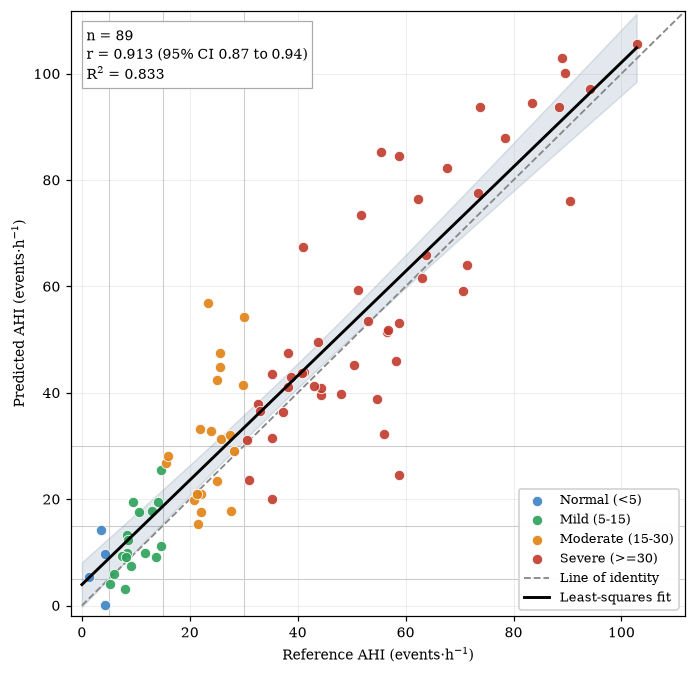

redrawn -> /home/nishant/apneastudyproject/AHI_calculation_results/figures/fig1_agreement_scatter.png


In [16]:
# =========================================================================
# CELL 12 — redraw Fig 1 with the annotation box fitted to its text
# =========================================================================
fig, ax = plt.subplots(figsize=(6.4, 6.2))

for i, (bn, bl) in enumerate(zip(BAND_NAMES, BAND_LABELS)):
    m = np.array([band_idx(v) == i for v in x])
    if m.any():
        ax.scatter(x[m], y[m], s=46, c=BAND_COLOR[i], alpha=.9, lw=.6,
                   edgecolors="white", zorder=3,
                   label=f"{bn} ({bl.split(chr(10))[1].strip('()')})")

hi = max(x.max(), y.max()) * 1.06
ax.plot([0, hi], [0, hi], ls="--", c="#888888", lw=1.2, zorder=2,
        label="Line of identity")
xs = np.linspace(0, x.max(), 100)
ax.plot(xs, intercept + slope*xs, c="#000000", lw=1.9, zorder=4,
        label="Least-squares fit")
sx = np.sqrt(((y - (intercept + slope*x))**2).sum() / (n - 2))
se_fit = sx * np.sqrt(1/n + (xs - x.mean())**2 / ((x - x.mean())**2).sum())
ax.fill_between(xs, intercept + slope*xs - 1.96*se_fit,
                intercept + slope*xs + 1.96*se_fit,
                color="#1F4E79", alpha=.13, zorder=1)

for v in AASM_BINS:
    ax.axvline(v, c="#CCCCCC", lw=.7, zorder=0)
    ax.axhline(v, c="#CCCCCC", lw=.7, zorder=0)

txt = (f"n = {n}\n"
       f"r = {r:.3f} (95% CI {r_lo:.2f} to {r_hi:.2f})\n"
       f"R$^2$ = {r**2:.3f}")
ax.text(.025, .975, txt, transform=ax.transAxes, va="top", ha="left",
        multialignment="left", fontsize=9.2, linespacing=1.35,
        bbox=dict(boxstyle="square,pad=0.34", fc="white", ec="#AAAAAA", lw=.8))

ax.set_xlabel("Reference AHI (events$\\cdot$h$^{-1}$)")
ax.set_ylabel("Predicted AHI (events$\\cdot$h$^{-1}$)")
ax.set_xlim(-2, hi); ax.set_ylim(-2, hi)
ax.legend(loc="lower right", fontsize=8.4, framealpha=.95)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig1_agreement_scatter.png"),
            dpi=250, bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR, "fig1_agreement_scatter.pdf"),
            bbox_inches="tight")
plt.show()
print(f"redrawn -> {os.path.join(FIG_DIR,'fig1_agreement_scatter.png')}")

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt, welch, decimate

rng = np.random.default_rng(7)
FS, DUR = 200.0, 120.0
t = np.arange(0, DUR, 1/FS)

# ---- heart rate: bradycardia during apnea, tachycardia at arousal --------
apnea = [(20,45),(62,86)]
hr = np.full_like(t, 68.0)
for a,b in apnea:
    hr[(t>=a)&(t<b)]      = 52          # bradycardia
    hr[(t>=b)&(t<b+8)]    = 92          # arousal surge
b_,a_ = butter(2, 0.05/(FS/2)); hr = filtfilt(b_,a_,hr)

# ---- synthesise ECG -----------------------------------------------------
phase = np.cumsum(hr/60.0)/FS
beats = np.where(np.diff(np.floor(phase))>0)[0]
ecg = np.zeros_like(t)
for i in beats:
    for amp,off,wid in ((-0.12,-0.018,0.008),(1.0,0.0,0.010),(-0.22,0.020,0.011),
                        (0.20,0.14,0.045),(0.10,-0.14,0.035)):
        ecg += amp*np.exp(-((t-t[i]-off)**2)/(2*wid**2))
# respiratory amplitude modulation, suppressed during apnea, surge at arousal
mod = 1 + 0.20*np.sin(2*np.pi*0.22*t)
for a,b in apnea:
    mod[(t>=a)&(t<b)] = 1 + 0.04*np.sin(2*np.pi*0.22*t[(t>=a)&(t<b)])
    s_ = (t>=b)&(t<b+7); mod[s_] *= 1.45                     # arousal surge
mod = filtfilt(*butter(2, 1.5/(FS/2)), mod)
ecg *= mod
ecg += 0.015*rng.standard_normal(t.size)

# ---- SpO2: desaturation trailing each apnea -----------------------------
spo2 = np.full_like(t, 96.5)
for a,b in apnea:
    d = (t>=b-2)&(t<b+14)
    spo2[d] -= 8.5*np.exp(-((t[d]-(b+5))**2)/(2*4.0**2))
spo2 = filtfilt(*butter(2, 0.4/(FS/2)), spo2) + 0.05*rng.standard_normal(t.size)

# ---- the three treatments ----------------------------------------------
env = np.abs(hilbert(ecg))
env = filtfilt(*butter(3, 0.45/(FS/2)), env)         # envelope, <0.45 Hz
t4  = np.arange(0, DUR, 1/4.0)
naive_ecg = np.interp(t4, t, ecg)                    # decimate raw -> alias
env_4     = np.interp(t4, t, env)
spo2_4    = np.interp(t4, t, spo2)

plt.rcParams.update({"font.family":"serif","font.size":8.5,"axes.linewidth":.8,
                     "axes.grid":True,"grid.alpha":.25,"grid.linewidth":.5})
fig = plt.figure(figsize=(7.16,5.7))
gs = fig.add_gridspec(3,2, height_ratios=[1,1,1.08], hspace=.72, wspace=.24)

def shade(ax):
    for a,b in apnea: ax.axvspan(a,b,color="#C0392B",alpha=.10,lw=0)

# (a) raw ECG
ax = fig.add_subplot(gs[0,:]); shade(ax)
ax.plot(t, ecg, lw=.45, c="#2C3E50")
ax.set_xlim(0,DUR); ax.set_ylabel("ECG (a.u.)")
ax.set_title("(a) Raw ECG at 200 Hz.  Shaded = apnea",
             fontsize=8.6, loc="left")
ax.set_xticklabels([])

# (b) zoom
ax = fig.add_subplot(gs[1,0])
z = (t>=30)&(t<34)
ax.plot(t[z], ecg[z], lw=.9, c="#2C3E50", label="200 Hz")
z4 = (t4>=30)&(t4<34)
ax.plot(t4[z4], naive_ecg[z4], "o-", ms=4, lw=1.2, c="#C0392B",
        label="decimated to 4 Hz")
ax.set_xlabel("time (s)"); ax.set_ylabel("ECG (a.u.)")
ax.set_title("(b) QRS is $\\approx$0.1 s wide", fontsize=8.6, loc="left")
ax.legend(fontsize=7, loc="upper right")

# (c) PSD
ax = fig.add_subplot(gs[1,1])
f1,P1 = welch(ecg, FS, nperseg=4096); f2,P2 = welch(env, FS, nperseg=4096)
f3,P3 = welch(spo2-spo2.mean(), FS, nperseg=4096)
ax.semilogy(f1,P1/P1.max(), lw=.9, c="#2C3E50", label="raw ECG")
ax.semilogy(f2,P2/P2.max(), lw=1.1, c="#2980B9", label="ECG envelope")
ax.semilogy(f3,P3/P3.max(), lw=1.1, c="#27AE60", label="SpO$_2$")
ax.axvline(2.0, c="#C0392B", ls="--", lw=1.1)
ax.text(2.5, 2e-6, "Nyquist for 4 Hz", fontsize=6.6, c="#C0392B", rotation=90)
ax.set_xlim(0,25); ax.set_ylim(1e-7,3)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("normalised PSD")
ax.set_title("(c) Where the energy lies", fontsize=8.6, loc="left")
ax.legend(fontsize=6.8, loc="upper right")

# (d) envelope route
ax = fig.add_subplot(gs[2,0]); shade(ax)
rc = np.corrcoef(np.interp(t,t4,env_4), env)[0,1]
rn = np.corrcoef(np.interp(t,t4,naive_ecg), ecg)[0,1]
ax.plot(t, env, lw=2.6, c="#B8C4CC", label="envelope @ 200 Hz")
ax.plot(t4, env_4, lw=1.0, c="#2980B9", label="envelope @ 4 Hz")
ax.set_xlim(0,DUR); ax.set_ylim(0, env.max()*1.42)
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude (a.u.)")
ax.set_title("(d) Envelope first, then decimate", fontsize=8.6, loc="left")
ax.legend(fontsize=7, loc="upper left", framealpha=.93)
ax.text(.985,.05,f"envelope route  r = {rc:.3f}\nnaive route      r = {rn:.2f}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=6.8,
        bbox=dict(fc="white",ec="#BBBBBB",lw=.6,pad=2.6))

# (e) SpO2
ax = fig.add_subplot(gs[2,1]); shade(ax)
ax.plot(t, spo2, lw=1.6, c="#95A5A6", label="200 Hz")
ax.plot(t4, spo2_4, "o", ms=2.2, c="#27AE60", label="4 Hz")
ax.axhline(96.5-3, ls=":", c="#C0392B", lw=1.0)
ax.text(2, 96.5-4.5, "3% desaturation threshold", fontsize=6.6, c="#C0392B")
ax.set_xlim(0,DUR); ax.set_ylim(85,99)
ax.set_xlabel("time (s)"); ax.set_ylabel("SpO$_2$ (%)")
ax.set_title("(e) SpO$_2$ is already slow", fontsize=8.6, loc="left")
ax.legend(fontsize=7, loc="lower right")

fig.savefig("resampling_rationale.png", dpi=250, bbox_inches="tight")
fig.savefig("resampling_rationale.pdf", bbox_inches="tight")

# quantitative support
def frac_below(f,P,c=2.0): return P[f<=c].sum()/P.sum()
print(f"raw ECG   energy below 2 Hz: {100*frac_below(f1,P1):.1f}%")
print(f"envelope  energy below 2 Hz: {100*frac_below(f2,P2):.1f}%")
print(f"SpO2      energy below 2 Hz: {100*frac_below(f3,P3):.1f}%")
print(f"corr(envelope@200, envelope@4 upsampled) = "
      f"{np.corrcoef(np.interp(t,t4,env_4), env)[0,1]:.4f}")
print(f"corr(spo2@200, spo2@4 upsampled)         = "
      f"{np.corrcoef(np.interp(t,t4,spo2_4), spo2)[0,1]:.4f}")
print(f"corr(raw ecg, naive 4Hz upsampled)       = "
      f"{np.corrcoef(np.interp(t,t4,naive_ecg), ecg)[0,1]:.4f}")

raw ECG   energy below 2 Hz: 18.7%
envelope  energy below 2 Hz: 100.0%
SpO2      energy below 2 Hz: 99.9%
corr(envelope@200, envelope@4 upsampled) = 1.0000
corr(spo2@200, spo2@4 upsampled)         = 0.9997
corr(raw ecg, naive 4Hz upsampled)       = 0.2123
